# Grad-CAM and Error Analysis
Owner: Shania

This notebook answers two questions about the trained CNN models:

1. **Where does the model go wrong?** Confusion matrix, false negatives (infected cells predicted as uninfected, the most dangerous error clinically), false positives, confidence of wrong predictions, and which patients the errors come from.
2. **What is the model looking at?** Grad-CAM heatmaps show which pixels drove each prediction. We check whether the model focuses on the parasite inside the cell, or on the black background/padding around it (a possible shortcut).

It uses the same frozen split (`data/splits/patient_split.csv`) and the same preprocessing as `03_cnn.ipynb` and `04_resnet18.ipynb`.

**Test-set rule:** following the team protocol, the models are now frozen (Anders, 22 Oct), so the final analysis runs on the held-out **test** split (`ANALYSIS_SPLIT = "test"`). The test metrics are checked against `artifacts/test_evaluation/`.

**Models:** loads Anders's trained models from `models/cnn.pt` and `models/resnet18.pt`, and checks that the validation metrics match the ones his notebooks reported.

## 0. Google Colab setup (run this first)
1. **Runtime → Change runtime type → T4 GPU**, then Save.
2. Upload **`DATA7703-Group-Project-main.zip`** (the ZIP from GitHub, which includes `models/cnn.pt` and `models/resnet18.pt`) to the main folder of your **Google Drive** ("My Drive"). Do not rename it.
3. Run the cell below. It connects Google Drive, unzips the project into Colab, and moves into the `notebooks` folder, so all `../data`, `../models` paths work exactly like on a laptop.

In [17]:
import glob, os, shutil, subprocess
from google.colab import drive

drive.mount("/content/drive")

def find_project():
    hits = glob.glob("/content/**/data/splits/patient_split.csv", recursive=True)
    hits = [h for h in hits if not h.startswith("/content/drive")]
    # Prefer the up-to-date project (the one that contains Anders's test evaluation)
    hits.sort(key=lambda h: not os.path.exists(os.path.join(h_root(h), "artifacts", "test_evaluation")))
    return h_root(hits[0]) if hits else None

def h_root(csv_path):
    return csv_path.rsplit("/data/splits/", 1)[0]

PROJECT_DIR = find_project()
if PROJECT_DIR is None:
    # Find the ZIP anywhere in My Drive (also works if it was renamed to "... (1).zip")
    zips = glob.glob("/content/drive/MyDrive/**/DATA7703-Group-Project*.zip", recursive=True)
    zips.sort(key=os.path.getmtime, reverse=True)   # newest upload first
    assert zips, "Could not find the DATA7703-Group-Project ZIP in Google Drive - upload it to My Drive first."
    print("Unzipping:", zips[0])
    shutil.unpack_archive(zips[0], "/content/project")
    PROJECT_DIR = find_project()

assert PROJECT_DIR is not None, "Unzipped, but data/splits/patient_split.csv was not found inside the ZIP."
os.chdir(os.path.join(PROJECT_DIR, "notebooks"))
print("Project folder:", PROJECT_DIR)
print("Working directory:", os.getcwd())
print("Split file found:", os.path.exists("../data/splits/patient_split.csv"))
print("Models found:", os.listdir("../models"))

# torch, torchvision, sklearn and pandas are preinstalled on Colab; make sure kagglehub is there too.
subprocess.run(["pip", "install", "-q", "kagglehub"], check=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/project/DATA7703-Group-Project-main
Working directory: /content/project/DATA7703-Group-Project-main/notebooks
Split file found: True
Models found: ['resnet18.pt', 'cnn.pt']


CompletedProcess(args=['pip', 'install', '-q', 'kagglehub'], returncode=0)

## 1. Setup and configuration

In [18]:
import sys
sys.path.append("..")

import json
import random
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score)
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights, resnet18

# ---- Configuration -------------------------------------------------------
MODEL_NAME = "smallcnn"      # "resnet18" or "smallcnn" -> run the notebook once for each
ANALYSIS_SPLIT = "test"      # models are frozen, so the final analysis uses the held-out test split
IMG_SIZE = 128
BATCH_SIZE = 64
SEED = 42
N_GALLERY = 8                # images shown per error/Grad-CAM gallery
# ---------------------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Using device:", device)

MODELS_DIR = Path("../models")
FIG_DIR = Path("../figures/gradcam_error_analysis") / MODEL_NAME / ANALYSIS_SPLIT
RESULTS_DIR = Path("../results")
for d in (MODELS_DIR, FIG_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

CLASS_TO_IDX = {"Uninfected": 0, "Parasitized": 1}
IDX_TO_CLASS = {v: k for k, v in CLASS_TO_IDX.items()}

Using device: cpu


## 2. Data: frozen split and shared preprocessing
Uses Shashank's shared `src/preprocessing.py` (`load_and_pad` + `normalize_image`), with each checkpoint's own declared normalisation: `zero_one` for the small CNN and `imagenet` for ResNet-18 (the same settings `scripts/evaluate_test_set.py` used).

In [19]:
from src.preprocessing import load_and_pad, normalize_image

NORMALIZE_METHOD = {"smallcnn": "zero_one", "resnet18": "imagenet"}[MODEL_NAME]


class CellDataset(Dataset):
    """Returns (model_input, label, index). The index lets us map predictions back to filenames."""
    def __init__(self, df: pd.DataFrame, data_dir: Path, normalize_method: str):
        self.df = df.reset_index(drop=True)
        self.data_dir = data_dir
        self.normalize_method = normalize_method

    def __len__(self):
        return len(self.df)

    def raw_image(self, idx: int) -> np.ndarray:
        row = self.df.iloc[idx]
        return load_and_pad(str(self.data_dir / row["category"] / row["filename"]), IMG_SIZE)

    def __getitem__(self, idx: int):
        img = normalize_image(self.raw_image(idx), method=self.normalize_method)
        x = torch.from_numpy(img.astype(np.float32)).permute(2, 0, 1)
        return x, CLASS_TO_IDX[self.df.iloc[idx]["category"]], idx


manifest = pd.read_csv("../data/splits/patient_split.csv")
print(manifest["split"].value_counts())

download_path = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
data_dir = download_path / "cell_images"
if (data_dir / "cell_images").exists():
    data_dir = data_dir / "cell_images"

train_ds = CellDataset(manifest[manifest["split"] == "train"], data_dir, NORMALIZE_METHOD)
val_ds = CellDataset(manifest[manifest["split"] == "val"], data_dir, NORMALIZE_METHOD)
analysis_ds = CellDataset(manifest[manifest["split"] == ANALYSIS_SPLIT], data_dir, NORMALIZE_METHOD)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
analysis_loader = DataLoader(analysis_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Analysis split: {ANALYSIS_SPLIT} ({len(analysis_ds)} images)")

split
train    19124
val       4324
test      4110
Name: count, dtype: int64
Using Colab cache for faster access to the 'cell-images-for-detecting-malaria' dataset.
Analysis split: test (4110 images)


## 3. Model definitions
Copied from `03_cnn.ipynb` and `04_resnet18.ipynb` so the architectures match exactly.

The **Grad-CAM target layer** is the last convolutional block of each network:
- Small CNN: the ReLU after the third convolution (`features[7]`), a 32×32 feature map. (The final small CNN replaces the large Flatten + Linear head with global average pooling, as in `03_cnn.ipynb`.)
- ResNet-18: `layer4[-1]`, a 4×4 feature map for 128×128 inputs, so its heatmaps are coarser.

In [20]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes: int = 2):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 128 -> 64
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 64 -> 32
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 32 -> 16
        )
        # Final architecture (matches 03_cnn.ipynb and scripts/evaluate_test_set.py):
        # global average pooling instead of Flatten + Linear(64*16*16, 128).
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_model(name: str, pretrained: bool = False):
    """Returns (model, Grad-CAM target layer, learning rate, epochs) matching the training notebooks.
    ImageNet weights are only downloaded if we have to train ResNet-18 ourselves."""
    if name == "smallcnn":
        m = SmallCNN()
        return m, m.features[7], 1e-3, 5
    if name == "resnet18":
        m = resnet18(weights=ResNet18_Weights.DEFAULT if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, 2)
        return m, m.layer4[-1], 1e-4, 3
    raise ValueError(f"Unknown model: {name}")


WEIGHT_FILES = {"smallcnn": "cnn.pt", "resnet18": "resnet18.pt"}   # file names Anders saves in models/
weights_path = MODELS_DIR / WEIGHT_FILES[MODEL_NAME]

model, target_layer, LR, NUM_EPOCHS = build_model(MODEL_NAME, pretrained=not weights_path.exists())
model = model.to(device)

## 4. Load Anders's trained models
Anders saved the trained models from `03_cnn.ipynb` and `04_resnet18.ipynb` as `models/cnn.pt` and `models/resnet18.pt` (pushed to `main`). This cell loads them, so the analysis uses exactly the same models as the reported results.

Fallback: if a weights file is missing, the cell trains the model with the same settings (seed, optimiser, learning rate, epochs) and saves it.

In [21]:
criterion = nn.CrossEntropyLoss()

checkpoint = None
if weights_path.exists():
    # Anders saves a dict: {"model_state_dict", "class_to_idx", "img_size", "val_metrics", ...}
    checkpoint = torch.load(weights_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    assert checkpoint["class_to_idx"] == CLASS_TO_IDX, "Class mapping differs from the training notebook!"
    assert checkpoint["img_size"] == IMG_SIZE, "Image size differs from the training notebook!"
    if "normalize_method" in checkpoint:
        assert checkpoint["normalize_method"] == NORMALIZE_METHOD, "Normalisation differs from the training notebook!"
    print(f"Loaded Anders's trained model from {weights_path}")
    history = None
else:
    print(f"No weights at {weights_path}: training {MODEL_NAME} for {NUM_EPOCHS} epochs (lr={LR})")
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = []
    for epoch in range(1, NUM_EPOCHS + 1):
        for phase, loader in (("train", train_loader), ("val", val_loader)):
            model.train(phase == "train")
            total_loss, correct, n = 0.0, 0, 0
            for x, y, _ in loader:
                x, y = x.to(device), y.to(device)
                with torch.set_grad_enabled(phase == "train"):
                    out = model(x)
                    loss = criterion(out, y)
                    if phase == "train":
                        optimizer.zero_grad()
                        loss.backward()
                        optimizer.step()
                total_loss += loss.item() * x.size(0)
                correct += (out.argmax(1) == y).sum().item()
                n += x.size(0)
            history.append({"epoch": epoch, "phase": phase, "loss": total_loss / n, "acc": correct / n})
        print(f"Epoch {epoch}: " + "  ".join(f"{h['phase']}_loss={h['loss']:.4f} {h['phase']}_acc={h['acc']:.4f}"
                                            for h in history[-2:]))
    torch.save({"model_state_dict": model.state_dict(), "class_to_idx": CLASS_TO_IDX, "img_size": IMG_SIZE}, weights_path)
    pd.DataFrame(history).to_csv(RESULTS_DIR / f"{MODEL_NAME}_history.csv", index=False)
    print(f"Saved weights to {weights_path}")

model.eval();

Loaded Anders's trained model from ../models/cnn.pt


## 5. Predictions on the analysis split

In [22]:
records = []
with torch.no_grad():
    for x, y, idx in analysis_loader:
        probs = F.softmax(model(x.to(device)), dim=1)[:, 1].cpu().numpy()   # P(Parasitized)
        for i, p, label in zip(idx.numpy(), probs, y.numpy()):
            records.append({"ds_index": int(i), "prob_parasitized": float(p), "label": int(label)})

pred = pd.DataFrame(records).sort_values("ds_index").reset_index(drop=True)
pred = pd.concat([analysis_ds.df[["filename", "patient_id", "category"]], pred], axis=1)
pred["pred"] = (pred["prob_parasitized"] >= 0.5).astype(int)
pred["confidence"] = np.where(pred["pred"] == 1, pred["prob_parasitized"], 1 - pred["prob_parasitized"])

def outcome(r):
    if r.label == 1 and r.pred == 1: return "TP"
    if r.label == 0 and r.pred == 0: return "TN"
    if r.label == 0 and r.pred == 1: return "FP"
    return "FN"

pred["outcome"] = pred.apply(outcome, axis=1)
pred.to_csv(RESULTS_DIR / f"{MODEL_NAME}_{ANALYSIS_SPLIT}_predictions.csv", index=False)
pred["outcome"].value_counts()

,count
outcome,
TN,2038
TP,1780
FN,187
FP,105


## 6. Overall metrics and confusion matrix
*Parasitized* is the positive class. **Recall** (sensitivity) matters most clinically: it is the share of infected cells the model catches.

,value
model,smallcnn
split,test
n_images,4110
accuracy,0.928954
precision,0.944297
recall,0.904931
specificity,0.951003
f1,0.924195
roc_auc,0.979249
false_negatives,187


Check against artifacts/test_evaluation (test):
  accuracy   saved=0.9290  here=0.9290
  precision  saved=0.9443  here=0.9443
  recall     saved=0.9049  here=0.9049
  f1         saved=0.9242  here=0.9242
  roc_auc    saved=0.9792  here=0.9792
  saved TN/FP/FN/TP = 2038/105/187/1780
  per-image agreement with saved predictions: 100.00% of 4110 images


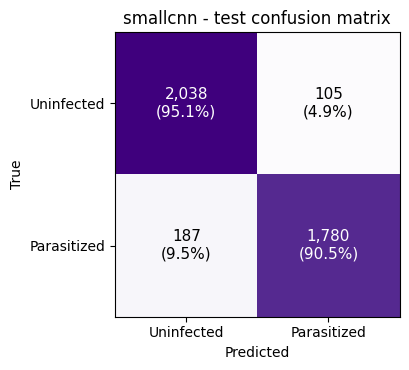

In [23]:
y_true, y_pred, y_prob = pred["label"], pred["pred"], pred["prob_parasitized"]
metrics = {
    "model": MODEL_NAME,
    "split": ANALYSIS_SPLIT,
    "n_images": int(len(pred)),
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred),
    "recall": recall_score(y_true, y_pred),
    "specificity": recall_score(y_true, y_pred, pos_label=0),
    "f1": f1_score(y_true, y_pred),
    "roc_auc": roc_auc_score(y_true, y_prob),
    "false_negatives": int((pred["outcome"] == "FN").sum()),
    "false_positives": int((pred["outcome"] == "FP").sum()),
}
with open(RESULTS_DIR / f"{MODEL_NAME}_{ANALYSIS_SPLIT}_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
display(pd.Series(metrics).to_frame("value"))

# Reproducibility check: on the validation split, these numbers should match what Anders's notebook
# reported at its final epoch (saved inside the checkpoint).
if checkpoint is not None and ANALYSIS_SPLIT == "val" and "val_metrics" in checkpoint:
    saved = checkpoint["val_metrics"]
    print("Check against the training notebook (val):")
    for k_saved, k_here in (("acc", "accuracy"), ("precision", "precision"), ("recall", "recall"),
                            ("f1", "f1"), ("roc_auc", "roc_auc")):
        print(f"  {k_here:<10} saved={saved[k_saved]:.4f}  here={metrics[k_here]:.4f}")
    print("  saved confusion matrix:\n", saved["cm"])

# Reproducibility check on the test split: compare with Anders's frozen test evaluation.
ARTIFACT_NAME = {"smallcnn": "cnn", "resnet18": "resnet18"}[MODEL_NAME]
test_eval_dir = Path("../artifacts/test_evaluation") / ARTIFACT_NAME
if ANALYSIS_SPLIT == "test" and test_eval_dir.exists():
    saved = json.loads((test_eval_dir / "test_metrics.json").read_text())
    print("Check against artifacts/test_evaluation (test):")
    for k in ("accuracy", "precision", "recall", "f1", "roc_auc"):
        print(f"  {k:<10} saved={saved[k]:.4f}  here={metrics[k]:.4f}")
    print(f"  saved TN/FP/FN/TP = {saved['tn']}/{saved['fp']}/{saved['fn']}/{saved['tp']}")
    saved_pred = pd.read_csv(test_eval_dir / "test_predictions.csv")
    merged = pred.merge(saved_pred[["filename", "y_pred"]], on="filename")
    agree = (merged["pred"] == merged["y_pred"]).mean()
    print(f"  per-image agreement with saved predictions: {agree:.2%} of {len(merged)} images")

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(4.2, 3.8))
ax.imshow(cm, cmap="Purples")
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
ax.set_xticks([0, 1], ["Uninfected", "Parasitized"])
ax.set_yticks([0, 1], ["Uninfected", "Parasitized"])
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title(f"{MODEL_NAME} - {ANALYSIS_SPLIT} confusion matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=200)
plt.show()

## 7. Error analysis
### 7.1 How confident is the model when it is wrong?
Confident mistakes are more worrying than borderline ones, because they cannot be caught by simply raising or lowering the threshold.

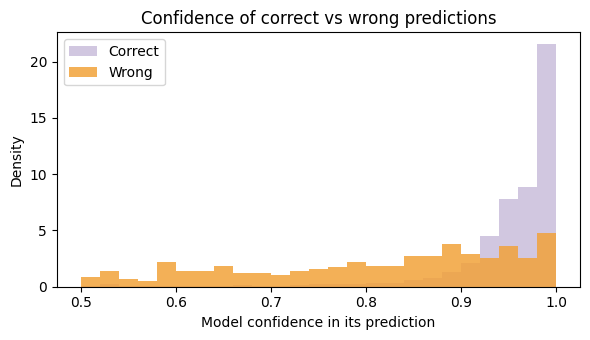

Wrong predictions: 292  |  of these, confidence > 0.9: 96


In [24]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(0.5, 1.0, 26)
for name, mask, color in (("Correct", pred["outcome"].isin(["TP", "TN"]), "#C9BEDB"),
                          ("Wrong", pred["outcome"].isin(["FP", "FN"]), "#F2A23A")):
    ax.hist(pred.loc[mask, "confidence"], bins=bins, alpha=0.85, label=name, color=color, density=True)
ax.set_xlabel("Model confidence in its prediction")
ax.set_ylabel("Density")
ax.set_title("Confidence of correct vs wrong predictions")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "confidence_correct_vs_wrong.png", dpi=200)
plt.show()

wrong = pred[pred["outcome"].isin(["FP", "FN"])]
print(f"Wrong predictions: {len(wrong)}  |  of these, confidence > 0.9: {(wrong['confidence'] > 0.9).sum()}")

### 7.2 Error galleries
The most confident false negatives and false positives, so we can look for visual causes: faint or small parasites, staining artefacts, debris, blur, or cells cut off at the image edge.

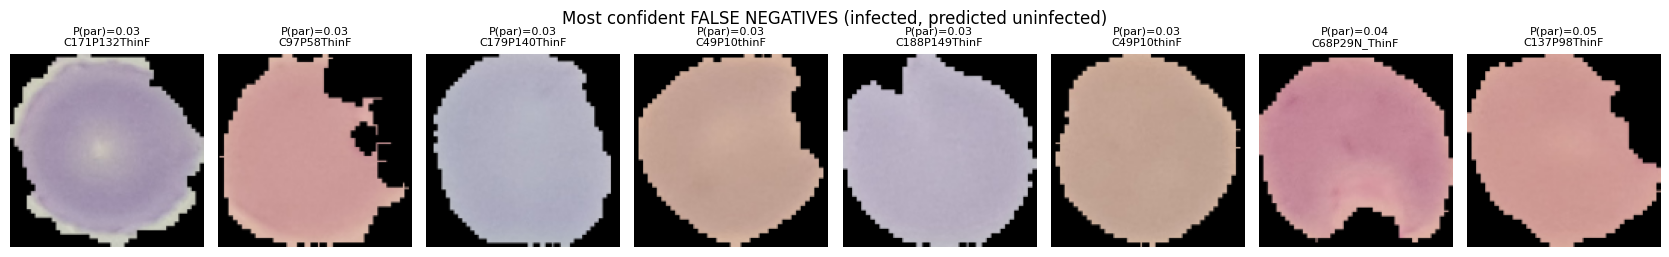

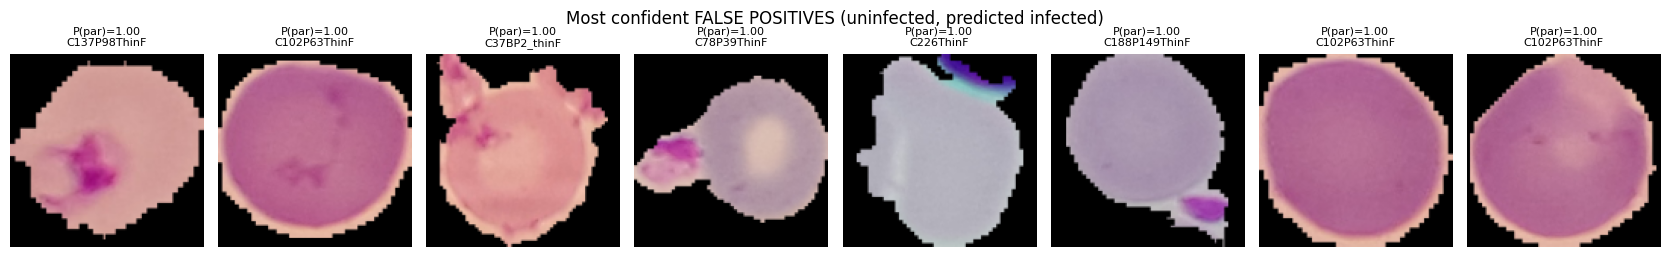

In [25]:
def show_gallery(rows: pd.DataFrame, title: str, fname: str):
    n = len(rows)
    if n == 0:
        print(f"No images for: {title}")
        return
    fig, axes = plt.subplots(1, n, figsize=(2.1 * n, 2.6))
    axes = np.atleast_1d(axes)
    for ax, (_, r) in zip(axes, rows.iterrows()):
        ax.imshow(analysis_ds.raw_image(int(r["ds_index"])))
        ax.set_title(f"P(par)={r['prob_parasitized']:.2f}\n{r['patient_id']}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=200)
    plt.show()

fn = pred[pred["outcome"] == "FN"].sort_values("confidence", ascending=False).head(N_GALLERY)
fp = pred[pred["outcome"] == "FP"].sort_values("confidence", ascending=False).head(N_GALLERY)
show_gallery(fn, "Most confident FALSE NEGATIVES (infected, predicted uninfected)", "gallery_false_negatives.png")
show_gallery(fp, "Most confident FALSE POSITIVES (uninfected, predicted infected)", "gallery_false_positives.png")

### 7.3 Are errors concentrated in a few patients?
Because the split is at patient level, we can check whether mistakes cluster in particular patients (for example, one slide with unusual staining). If a few patients account for most errors, the model may struggle with slide-level variation rather than with individual cells.

Patients in split: 31  |  top 10 patients hold 78% of all errors


,images,errors,fn,fp,error_rate
patient_id,,,,,
C68P29N_ThinF,702,77,76,1,0.109687
C102P63ThinF,103,48,3,45,0.466019
C49P10thinF,104,25,25,0,0.240385
C137P98ThinF,408,18,15,3,0.044118
C97P58ThinF,310,13,12,1,0.041935
C38P3thinF_original,75,12,2,10,0.160000
C188P149ThinF,128,10,9,1,0.078125
C174P135NThinF,182,9,4,5,0.049451
C187P148NThinF,91,8,7,1,0.087912


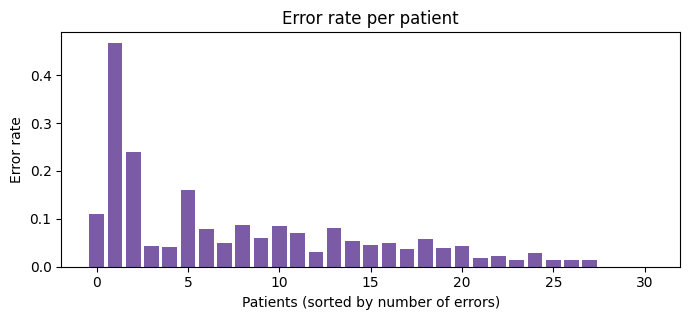

In [26]:
per_patient = (pred.assign(error=pred["outcome"].isin(["FP", "FN"]))
               .groupby("patient_id")
               .agg(images=("filename", "count"), errors=("error", "sum"),
                    fn=("outcome", lambda s: (s == "FN").sum()),
                    fp=("outcome", lambda s: (s == "FP").sum()))
               .assign(error_rate=lambda d: d["errors"] / d["images"])
               .sort_values("errors", ascending=False))
per_patient.to_csv(RESULTS_DIR / f"{MODEL_NAME}_{ANALYSIS_SPLIT}_errors_per_patient.csv")

top = per_patient.head(10)
share = top["errors"].sum() / max(per_patient["errors"].sum(), 1)
print(f"Patients in split: {len(per_patient)}  |  top 10 patients hold {share:.0%} of all errors")
display(top)

fig, ax = plt.subplots(figsize=(7, 3.3))
ax.bar(range(len(per_patient)), per_patient["error_rate"].values, color="#7B5AA6")
ax.set_xlabel("Patients (sorted by number of errors)")
ax.set_ylabel("Error rate")
ax.set_title("Error rate per patient")
plt.tight_layout()
plt.savefig(FIG_DIR / "error_rate_per_patient.png", dpi=200)
plt.show()

### 7.4 Do errors depend on image size?
Images are padded to a square with black borders. Small original images get scaled up; very non-square images get large black bands. If error rates differ by original size, preprocessing may be affecting performance.

In [27]:
meta = pd.read_csv("../data/raw/image_metadata.csv")[["filename", "height", "width"]]
sized = pred.merge(meta, on="filename", how="left")
sized["max_side"] = sized[["height", "width"]].max(axis=1)
sized["size_bin"] = pd.qcut(sized["max_side"], q=4, duplicates="drop")
size_table = (sized.assign(error=sized["outcome"].isin(["FP", "FN"]))
              .groupby("size_bin", observed=True)
              .agg(images=("filename", "count"), error_rate=("error", "mean")))
display(size_table)

,images,error_rate
size_bin,,
"(69.999, 127.0]",1156,0.068339
"(127.0, 139.0]",1169,0.058169
"(139.0, 151.0]",894,0.072707
"(151.0, 346.0]",891,0.089787


## 8. Grad-CAM
Grad-CAM (Selvaraju et al., 2017) takes the gradient of the class score with respect to the last convolutional feature maps, averages it into one weight per channel, and builds a weighted heatmap. Red areas are the regions that pushed the model towards its prediction.

We compute the heatmap for the **predicted** class, so for errors it shows what misled the model.

In [28]:
class GradCAM:
    def __init__(self, model: nn.Module, layer: nn.Module):
        self.model = model
        self.activations = None
        self.gradients = None
        layer.register_forward_hook(self._hook)

    def _hook(self, module, inp, out):
        # Save the feature maps, and attach a hook to the same tensor to catch its gradient.
        self.activations = out.detach()
        if out.requires_grad:
            out.register_hook(self._save_gradient)

    def _save_gradient(self, grad):
        self.gradients = grad.detach()

    def __call__(self, x: torch.Tensor, class_idx: int) -> np.ndarray:
        self.model.zero_grad()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        score = self.model(x)[0, class_idx]
        score.backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)          # one weight per channel
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam - cam.min()
        return (cam / (cam.max() + 1e-8)).cpu().numpy()


gradcam = GradCAM(model, target_layer)

def cam_for_row(r):
    x, _, _ = analysis_ds[int(r["ds_index"])]
    return gradcam(x, int(r["pred"]))

### 8.1 Grad-CAM galleries: correct vs wrong predictions
Top row: original cell. Bottom row: Grad-CAM overlay for the predicted class.

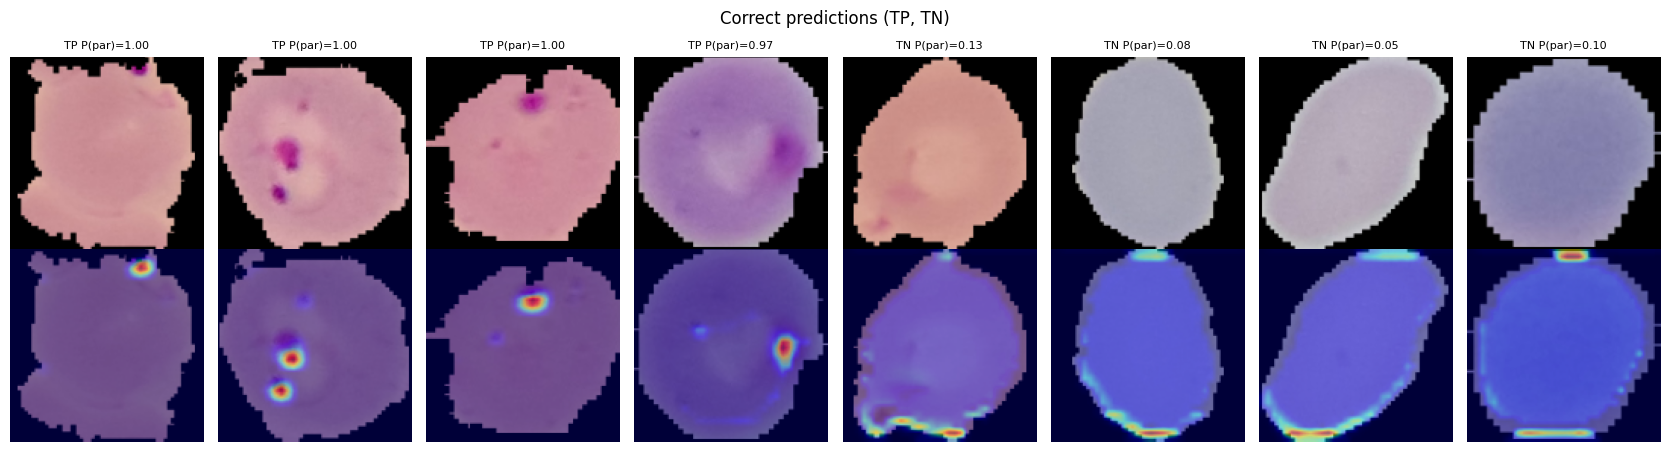

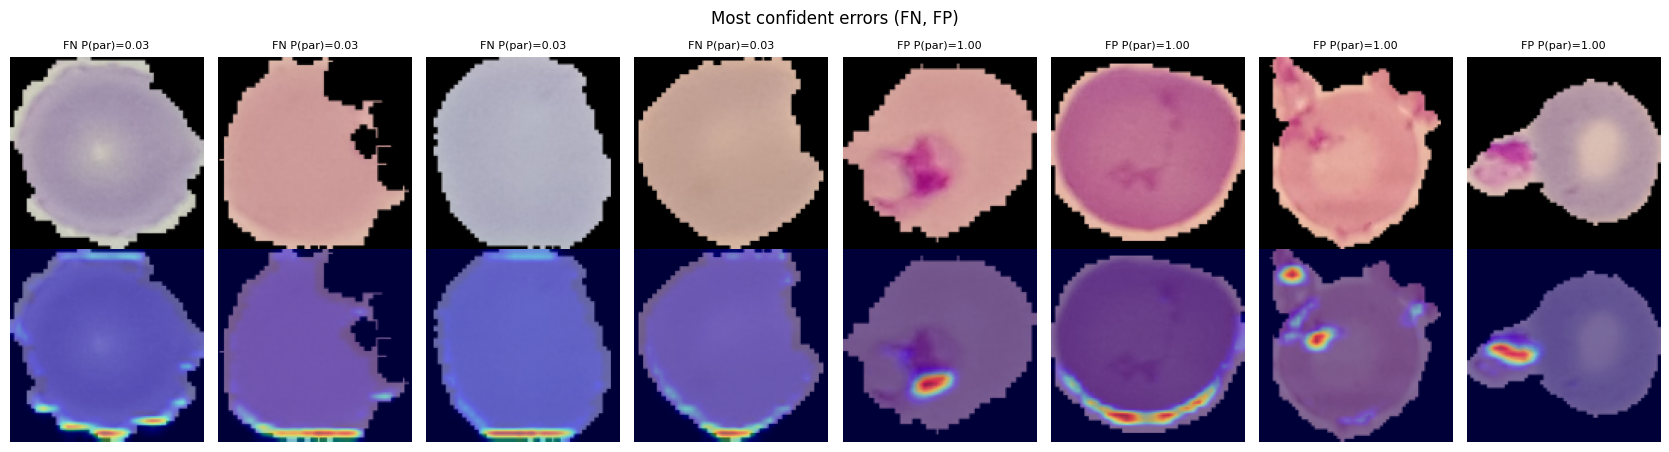

In [29]:
def gradcam_gallery(rows: pd.DataFrame, title: str, fname: str):
    n = len(rows)
    if n == 0:
        print(f"No images for: {title}")
        return
    fig, axes = plt.subplots(2, n, figsize=(2.1 * n, 4.6))
    axes = np.array(axes).reshape(2, n)
    for j, (_, r) in enumerate(rows.iterrows()):
        img = analysis_ds.raw_image(int(r["ds_index"]))
        cam = cam_for_row(r)
        axes[0, j].imshow(img)
        axes[0, j].set_title(f"{r['outcome']} P(par)={r['prob_parasitized']:.2f}", fontsize=8)
        axes[1, j].imshow(img)
        axes[1, j].imshow(cam, cmap="jet", alpha=0.45)
        axes[0, j].axis("off"); axes[1, j].axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(FIG_DIR / fname, dpi=200)
    plt.show()

k = max(N_GALLERY // 2, 1)
sample = lambda o, s: pred[pred["outcome"] == o].sample(min(k, (pred["outcome"] == o).sum()), random_state=s)
gradcam_gallery(pd.concat([sample("TP", 1), sample("TN", 2)]), "Correct predictions (TP, TN)", "gradcam_correct.png")
gradcam_gallery(pd.concat([fn.head(k), fp.head(k)]), "Most confident errors (FN, FP)", "gradcam_errors.png")

### 8.2 Is the model looking at the cell or at the background?
A quantitative check of the *background/boundary* concern. For each image we build a **cell mask** (pixels that are not black, i.e. not background or padding) and compute the share of Grad-CAM attention that falls **outside** the cell.

- Close to 0: the model looks at the cell itself.
- High values: the model relies on the border, padding or background. That is a shortcut that may not generalise.

We compare this share between correct and wrong predictions on a random sample.

,count,mean,50%
outcome,,,
FN,131.0,0.036709,0.034057
FP,69.0,0.002359,0.001235
TN,90.0,0.044328,0.038938
TP,110.0,0.005721,0.001635


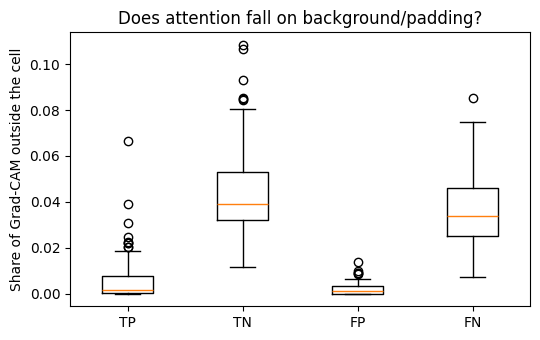

In [30]:
N_CAM_SAMPLE = 400   # Grad-CAM is one forward + backward pass per image; increase if time allows
BLACK_THRESHOLD = 0.06

def outside_cell_share(r) -> float:
    img = analysis_ds.raw_image(int(r["ds_index"]))
    cell_mask = img.max(axis=2) > BLACK_THRESHOLD
    cam = cam_for_row(r)
    return float(cam[~cell_mask].sum() / (cam.sum() + 1e-8))

sample_rows = pd.concat([
    pred[pred["outcome"].isin(["TP", "TN"])].sample(min(N_CAM_SAMPLE // 2, (pred["outcome"].isin(["TP", "TN"])).sum()), random_state=SEED),
    pred[pred["outcome"].isin(["FP", "FN"])].sample(min(N_CAM_SAMPLE // 2, (pred["outcome"].isin(["FP", "FN"])).sum()), random_state=SEED),
])
sample_rows["outside_share"] = [outside_cell_share(r) for _, r in sample_rows.iterrows()]
sample_rows["correct"] = sample_rows["outcome"].isin(["TP", "TN"])
sample_rows.to_csv(RESULTS_DIR / f"{MODEL_NAME}_{ANALYSIS_SPLIT}_gradcam_outside_share.csv", index=False)

summary = sample_rows.groupby("outcome")["outside_share"].describe()[["count", "mean", "50%"]]
display(summary)

fig, ax = plt.subplots(figsize=(5.5, 3.5))
order = [o for o in ["TP", "TN", "FP", "FN"] if o in sample_rows["outcome"].unique()]
ax.boxplot([sample_rows.loc[sample_rows["outcome"] == o, "outside_share"] for o in order])
ax.set_xticks(range(1, len(order) + 1), order)
ax.set_ylabel("Share of Grad-CAM outside the cell")
ax.set_title("Does attention fall on background/padding?")
plt.tight_layout()
plt.savefig(FIG_DIR / "gradcam_outside_cell_share.png", dpi=200)
plt.show()

In [31]:
def background_fraction(r):
    img = analysis_ds.raw_image(int(r["ds_index"]))
    return float((img.max(axis=2) <= BLACK_THRESHOLD).mean())

sample_rows["background_fraction"] = [background_fraction(r) for _, r in sample_rows.iterrows()]
sample_rows["excess_outside"] = sample_rows["outside_share"] - sample_rows["background_fraction"]
display(sample_rows.groupby("outcome")[["background_fraction", "outside_share", "excess_outside"]].mean())

,background_fraction,outside_share,excess_outside
outcome,,,
FN,0.374780,0.036709,-0.338071
FP,0.348916,0.002359,-0.346557
TN,0.337140,0.044328,-0.292812
TP,0.353994,0.005721,-0.348273


## 9. Summary for the slides and report
Fill this in after running the notebook on the **test** split for **both** models (`MODEL_NAME = "smallcnn"` and `"resnet18"`).

| | Small CNN | ResNet-18 |
|---|---|---|
| Recall (infected cells caught) | | |
| False negatives | | |
| Wrong predictions with confidence > 0.9 | | |
| Top 10 patients' share of errors | | |
| Mean Grad-CAM share outside the cell (correct / wrong) | | |

**Key observations (2–4 bullet points):**
- What do false negatives have in common? (for example faint or small parasites, unusual staining)
- What do false positives have in common? (for example debris, platelets, stain artefacts that look like parasites)
- Does the model focus on the parasite, or on the background or padding?
- Are errors spread evenly, or concentrated in a few patients or slides?

All figures are saved in `figures/gradcam_error_analysis/<model>/<split>/`, and tables in `results/`.

## 10. Save results to Google Drive
Colab deletes its files when the session ends, so this copies `figures/` and `results/` to **My Drive → DATA7703_gradcam_outputs**. Run it after each model (`resnet18`, then `smallcnn`).

In [32]:
OUT_DRIVE = "/content/drive/MyDrive/DATA7703_gradcam_outputs"
for folder in ("figures", "results"):
    src = os.path.join(PROJECT_DIR, folder)
    if os.path.exists(src):
        shutil.copytree(src, os.path.join(OUT_DRIVE, folder), dirs_exist_ok=True)
print("Saved to Google Drive:", OUT_DRIVE)

Saved to Google Drive: /content/drive/MyDrive/DATA7703_gradcam_outputs
